# econoAR · Tablero macroeconómico federal de la Argentina con IA

**Programación para Economistas · Segundo parcial** — UCA, Licenciatura en Administración de Empresas
Integrantes: _[completar]_ · Fecha: octubre 2026

| Apartado de la consigna | Respuesta |
|---|---|
| **1. Clasificación del producto** | Interfaz / dashboard interactivo (Streamlit) que integra un **modelo predictivo** (pronóstico de inflación), **aprendizaje no supervisado** (tipología de aglomerados) y un **asistente con IA generativa** (Claude) que responde preguntas y redacta un informe ejecutivo. |
| **2. Objetivo** | Reunir en un solo lugar los principales datos macroeconómicos de la Argentina —no solo a nivel país sino también por **región, provincia y aglomerado urbano**— y convertirlos en información útil: tendencias, comparaciones territoriales, pronósticos y explicaciones en lenguaje natural. |
| **3. Descripción general** | econoAR baja series oficiales de la API de Series de Tiempo de datos.gob.ar (INDEC, BCRA, Ministerio de Economía, SIPA), procesa los **microdatos de la EPH**, y las combina con informes técnicos del INDEC (pobreza, IPC, exportaciones por provincia), el Censo 2022, el **Producto Bruto Geográfico** de la CEPAL, las **ejecuciones presupuestarias provinciales** y la **mora** por provincia, y las muestra en un tablero con mapas, gráficos, modelos y un chat. |
| **4. Funcionalidad** | (a) Panel nacional: inflación, PIB/EMAE, industria, construcción, consumo, desocupación, actividad (oferta laboral), empleo registrado por modalidad, masa salarial, ingresos y Gini, pobreza, salarios reales, crédito y mora, resultado fiscal, reservas, tipo de cambio y comercio. (b) Mapa de las 24 jurisdicciones con 44 indicadores en 6 temas (trabajo; ingresos y salarios; PBG; finanzas provinciales; mora; población). (c) Ranking de los 31 aglomerados de la EPH. (d) Pronóstico de inflación con validación fuera de muestra. (e) Ley de Okun, regresiones de pobreza y de mora, y convergencia regional. (f) Clustering de aglomerados. (g) Asistente IA + informe automático. |
| **5. Usuarios** | Estudiantes y docentes de economía, periodistas, analistas de pymes y de gobiernos provinciales/municipales que necesitan comparar su jurisdicción con el resto del país sin bajar y limpiar decenas de planillas. |
| **6. Tecnología** | Python 3 · pandas, numpy, requests · statsmodels (ARIMA, MCO con errores robustos) · scikit-learn (Ridge, K-means, PCA) · matplotlib / geopandas / plotly · Streamlit · API de Anthropic (Claude) · API de Series de Tiempo de datos.gob.ar. |
| **7. Prototipo** | `streamlit run app.py` (este repositorio) y versión web publicada (ver informe). |

> **Cómo correr este notebook en Google Colab:** subí la carpeta `econoAR` comprimida (`econoAR.zip`) a la sesión y ejecutá la primera celda; descomprime el proyecto e instala lo que falte.

In [1]:
# --- Preparación del entorno (Colab o local) ---
import os, sys, zipfile
if os.path.exists("econoAR.zip") and not os.path.exists("econoAR"):
    zipfile.ZipFile("econoAR.zip").extractall(".")
for ruta in ["econoAR", "..", "."]:
    if os.path.exists(os.path.join(ruta, "econoar", "datos.py")):
        sys.path.insert(0, os.path.abspath(ruta)); break
try:
    import statsmodels, sklearn, geopandas  # noqa
except ImportError:
    !pip -q install statsmodels scikit-learn geopandas

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from econoar import series as S, datos as D, modelos as M, ia

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
AZUL, NARANJA, VERDE, ROJO, GRIS = "#2563eb", "#ea580c", "#16a34a", "#dc2626", "#64748b"
mpl.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "font.size": 10.5})

## 1. Importación de datos

La fuente principal es la **API de Series de Tiempo** (`apis.datos.gob.ar/series/api`). El módulo `econoar.series` tiene el catálogo de identificadores (IPC nacional y por región, EMAE, PIB, EPH, salarios, IMIG, BCRA, ICA y SIPA por provincia) y un cliente que:

* pide **una serie por llamada** (la API devuelve huecos intermitentes cuando se piden varias juntas), y
* **repite el pedido y une los resultados**, porque algunas observaciones faltan al azar en respuestas individuales.

Como respaldo, el proyecto trae un *snapshot* en `data/` armado el 14-10-2026 con la misma API y con informes técnicos del INDEC (EPH 2T-2026, pobreza 1S-2026, IPC septiembre 2026, OPEX 1S-2026) y el Censo 2022. La ampliación suma:

| Bloque | Fuente | Archivo |
|---|---|---|
| Empleo registrado por modalidad, remuneración y masa salarial | SIPA (API, catálogo `S.AMPLIADAS`) | `mensual_ampliado.csv` |
| Préstamos en pesos, tasa de tarjetas e irregularidad (mora) bancaria | BCRA (API) | `mensual_ampliado.csv` |
| IPI, ISAC, supermercados, Gini | INDEC (API) | `mensual_ampliado.csv` |
| Ingresos e informalidad por aglomerado | **Microdatos EPH 1T-2026** (`econoar.eph`) | `eph_ingresos_1T2026.csv` |
| Producto Bruto Geográfico 2004-2023 | CEPAL / Min. Economía (vía Argendata) | `pbg_provincias_cepal.csv` |
| Ejecución presupuestaria 2025 por provincia | Dirección Nacional de Asuntos Provinciales | `fiscal_provincias_2025.csv` |
| Mora de personas por provincia y por edad | Centro de Economía y Comunicación (Central de Deudores BCRA), CEPA | `mora_*.csv` |
| Salario privado registrado por provincia | OEDE (Secretaría de Trabajo) | `salarios_provincias_mar2026.csv` |

In [3]:
# Demostración del cliente: inflación y actividad en vivo (si hay internet)
try:
    ipc_vivo = S.descargar_serie(S.MENSUALES["ipc_nivel_general"].id, start_date="2024-01-01", intentos=2, timeout=10)
    print(f"API OK · IPC nivel general: {len(ipc_vivo)} observaciones, última {ipc_vivo.index[-1]:%m-%Y}")
    display(ipc_vivo.tail(3).to_frame("IPC"))
except ConnectionError as e:
    print("Sin conexión a la API → se trabaja con el snapshot local del 14-10-2026.")

USAR_API_COMPLETA = False   # True: actualiza todas las series (~1-2 min); False: snapshot
datos = D.cargar_snapshot()
if USAR_API_COMPLETA:
    datos = D.actualizar_desde_api(datos)
print("Origen de los datos:", datos.origen)
print({k: getattr(datos, k).shape for k in ["mensual", "trimestral", "aglomerados", "provincias", "sipa_mensual",
                                            "ampliado", "pbg", "fiscal_prov", "mora_prov", "ingresos_aglo"]})

Sin conexión a la API → se trabaja con el snapshot local del 14-10-2026.
Origen de los datos: snapshot 14-10-2026
{'mensual': (117, 25), 'trimestral': (42, 11), 'aglomerados': (42, 13), 'provincias': (24, 53), 'sipa_mensual': (42, 24), 'ampliado': (116, 21), 'pbg': (480, 4), 'fiscal_prov': (25, 14), 'mora_prov': (25, 2), 'ingresos_aglo': (39, 9)}


In [4]:
datos.mensual.tail(3).T

fecha,2026-07-01,2026-08-01,2026-09-01
ipc_nivel_general,"12,076.39","12,276.77","12,514.92"
ipc_nucleo,"12,224.36","12,445.80","12,654.01"
ipc_regulados,"12,652.98","12,935.97","13,236.47"
ipc_estacionales,"10,180.34","10,092.35","10,386.46"
ipc_gba,"12,078.74","12,276.81","12,520.11"
ipc_pampeana,"12,027.53","12,224.00","12,467.16"
ipc_cuyo,"12,160.23","12,360.91","12,591.72"
ipc_patagonia,"12,051.11","12,265.27","12,435.49"
ipc_noreste,"12,190.82","12,404.68","12,618.07"
ipc_noroeste,NaN,"12,397.94","12,632.64"


## 2. Procesamiento

* **Precios:** variaciones mensuales e interanuales; los huecos de las series regionales se interpolan en logaritmos (solo hacia adentro).
* **Salario real:** índice de salarios INDEC / IPC, base noviembre 2023 = 100.
* **Fiscal:** resultado primario y financiero anual en % del PIB. Las series trimestrales de PIB de la API están en **niveles anualizados**, por eso el PIB del año es el *promedio* de los cuatro trimestres.
* **Provincias:** se cruzan Censo 2022, SIPA (último dato y variaciones), exportaciones OPEX y el aglomerado EPH principal de cada provincia.

In [5]:
infl = D.inflacion(datos)
ult = infl.dropna(subset=["general_mm"]).iloc[-1]
print(f"Inflación {infl['general_mm'].dropna().index[-1]:%m-%Y}: {ult.general_mm:.1f}% m/m · {ult.general_ia:.1f}% i/a · núcleo {ult.nucleo_mm:.1f}%")
display(infl[["general_mm", "nucleo_mm", "regulados_mm", "estacionales_mm", "general_ia"]].dropna().tail(6).round(2))

Inflación 09-2026: 1.9% m/m · 33.4% i/a · núcleo 1.7%


,general_mm,nucleo_mm,regulados_mm,estacionales_mm,general_ia
fecha,,,,,
2026-04-01,2.58,2.29,4.68,-0.05,32.35
2026-05-01,2.15,1.90,2.40,3.48,33.20
2026-06-01,1.89,1.57,2.30,3.38,33.55
2026-07-01,2.11,1.78,2.13,4.54,33.83
2026-08-01,1.66,1.81,2.24,-0.86,33.54
2026-09-01,1.94,1.67,2.32,2.91,33.36


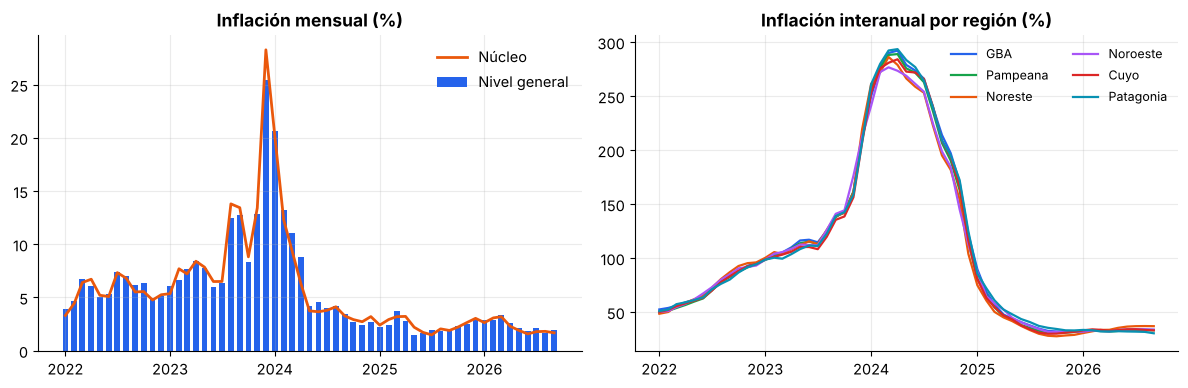

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
i = infl[infl.index >= "2022-01-01"]
ax[0].bar(i.index, i["general_mm"], width=20, color=AZUL, label="Nivel general")
ax[0].plot(i.index, i["nucleo_mm"], color=NARANJA, lw=2, label="Núcleo")
ax[0].set_title("Inflación mensual (%)"); ax[0].legend(frameon=False)
for reg, col in zip(D.REGIONES_IPC.values(), [AZUL, VERDE, NARANJA, "#a855f7", ROJO, "#0891b2"]):
    ax[1].plot(i.index, i[f"{reg}_ia"].interpolate(limit_area="inside"), lw=1.6, color=col, label=reg)
ax[1].set_title("Inflación interanual por región (%)"); ax[1].legend(frameon=False, ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

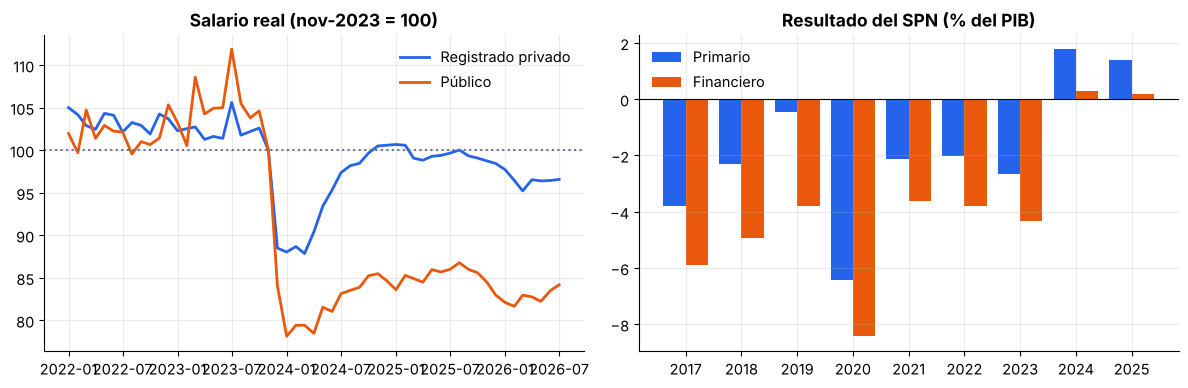

fecha,2017,2018,2019,2020,2021,2022,2023,2024,2025
resultado_primario,-3.79,-2.30,-0.44,-6.43,-2.12,-2.00,-2.66,1.78,1.38
resultado_financiero,-5.90,-4.94,-3.80,-8.43,-3.60,-3.81,-4.34,0.30,0.17
intereses,2.11,2.64,3.36,2.00,1.48,1.80,1.68,1.48,1.21


In [7]:
sr = D.salario_real(datos)
fp = D.fiscal_pct_pib(datos)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s2 = sr[sr.index >= "2022-01-01"]
ax[0].plot(s2.index, s2["real_reg_privado"], color=AZUL, lw=2, label="Registrado privado")
ax[0].plot(s2.index, s2["real_publico"], color=NARANJA, lw=2, label="Público")
ax[0].axhline(100, color=GRIS, ls=":"); ax[0].set_title("Salario real (nov-2023 = 100)"); ax[0].legend(frameon=False)
x = np.arange(len(fp))
ax[1].bar(x - .2, fp["resultado_primario"], .4, color=AZUL, label="Primario")
ax[1].bar(x + .2, fp["resultado_financiero"], .4, color=NARANJA, label="Financiero")
ax[1].set_xticks(x, fp.index); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Resultado del SPN (% del PIB)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
fp.round(2).T

## 3. Mercado de trabajo, pobreza y territorio

La EPH releva **31 aglomerados urbanos**. La tasa de **actividad** (PEA / población) es la medida de **oferta laboral**; la de **empleo** mide la demanda efectivamente cubierta; la **desocupación** la brecha. Para la demanda de trabajo formal por provincia se usa el **SIPA** (asalariados privados registrados).

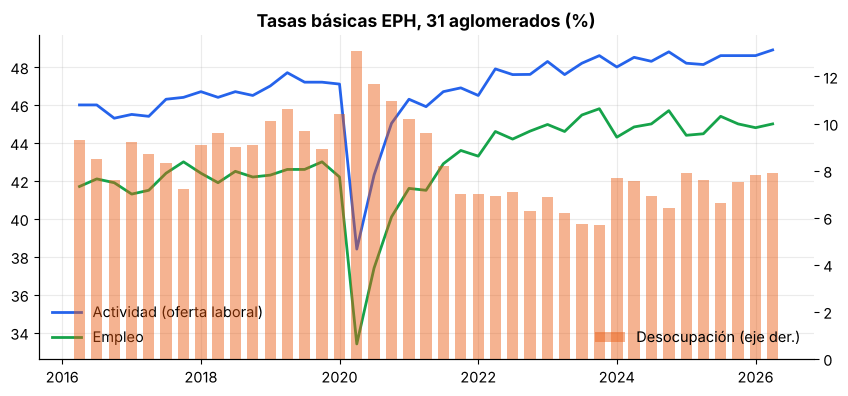

In [8]:
t = datos.trimestral.dropna(subset=["desocupacion"])
fig, ax = plt.subplots()
ax.plot(t.index, t["actividad"], color=AZUL, lw=2, label="Actividad (oferta laboral)")
ax.plot(t.index, t["empleo"], color=VERDE, lw=2, label="Empleo")
ax2 = ax.twinx(); ax2.bar(t.index, t["desocupacion"], width=60, color=NARANJA, alpha=.45, label="Desocupación (eje der.)")
ax.set_title("Tasas básicas EPH, 31 aglomerados (%)"); ax.legend(loc="lower left", frameon=False); ax2.legend(loc="lower right", frameon=False)
ax2.grid(False); plt.show()

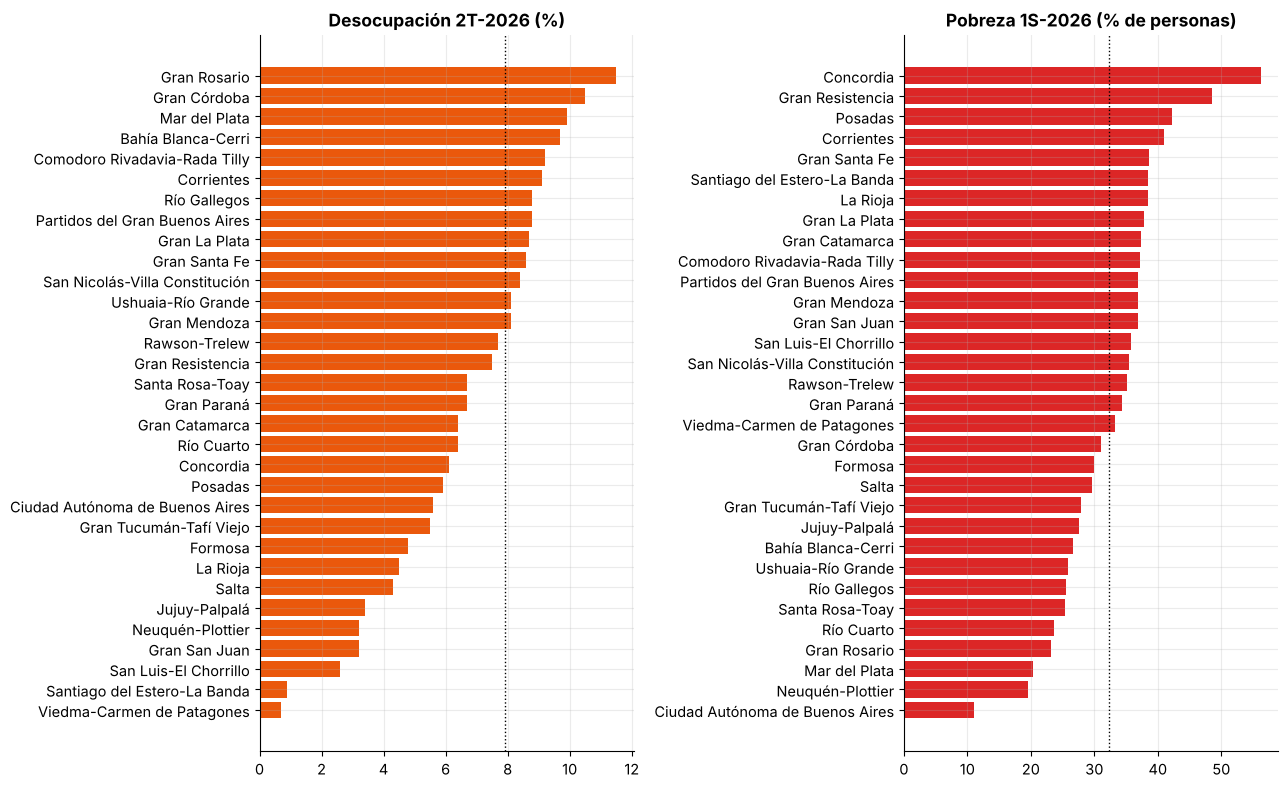

In [9]:
a = datos.aglomerados[datos.aglomerados.tipo == "aglomerado"].sort_values("tasa_desocupacion")
fig, ax = plt.subplots(1, 2, figsize=(13, 8), sharey=False)
ax[0].barh(a["nombre"], a["tasa_desocupacion"], color=NARANJA); ax[0].axvline(7.9, color="k", ls=":", lw=1)
ax[0].set_title("Desocupación 2T-2026 (%)")
b = a.sort_values("personas_pobreza")
ax[1].barh(b["nombre"], b["personas_pobreza"], color=ROJO); ax[1].axvline(32.3, color="k", ls=":", lw=1)
ax[1].set_title("Pobreza 1S-2026 (% de personas)")
plt.tight_layout(); plt.show()

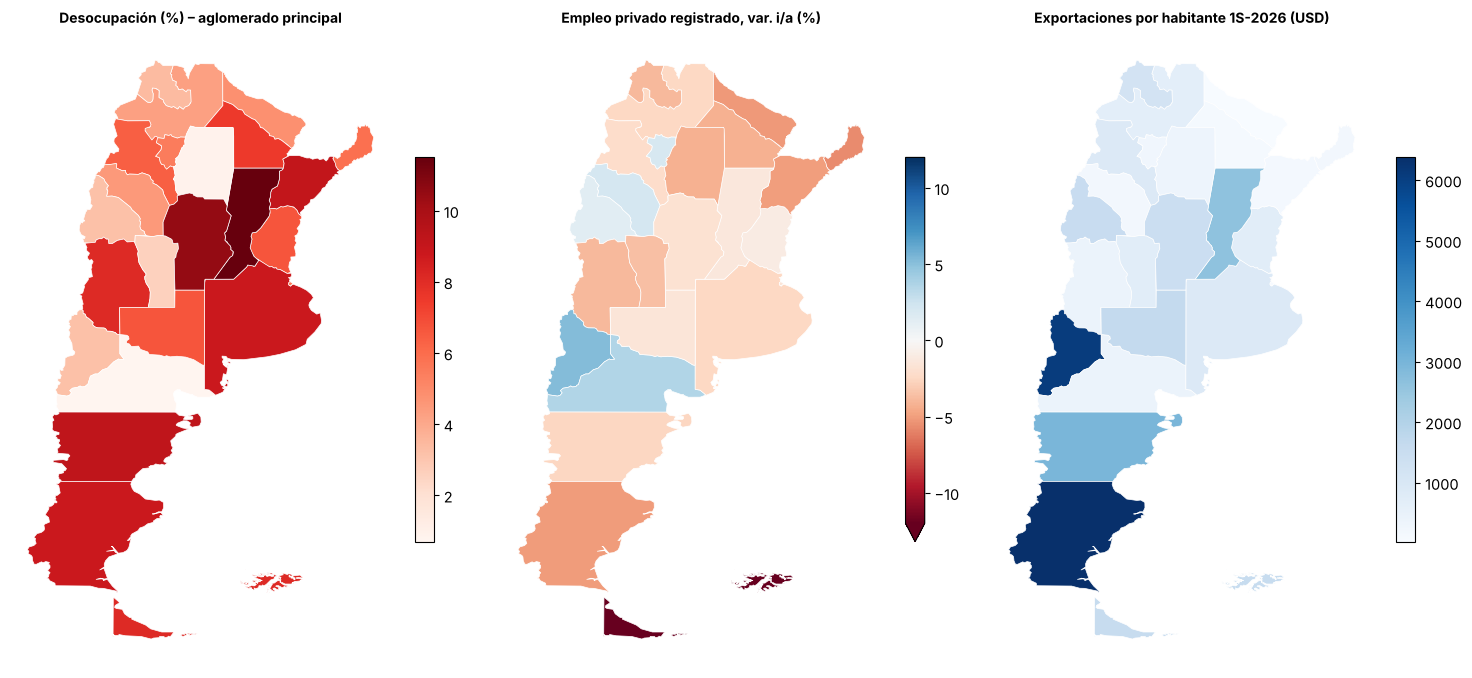

In [10]:
import geopandas as gpd
gdf = gpd.GeoDataFrame.from_features(datos.geojson["features"]).merge(datos.provincias, on="provincia")
fig, ax = plt.subplots(1, 3, figsize=(15, 8))
for eje, col, cmap, tit in [(ax[0], "tasa_desocupacion", "Reds", "Desocupación (%) – aglomerado principal"),
                            (ax[1], "empleo_privado_var_ia", "RdBu", "Empleo privado registrado, var. i/a (%)"),
                            (ax[2], "expo_usd_por_hab", "Blues", "Exportaciones por habitante 1S-2026 (USD)")]:
    kw = dict(vmin=-12, vmax=12) if cmap == "RdBu" else {}
    gdf.plot(column=col, cmap=cmap, legend=True, ax=eje, edgecolor="white", linewidth=.5,
             legend_kwds={"shrink": .5}, **kw)
    eje.set_title(tit, fontsize=10); eje.set_axis_off()
plt.tight_layout(); plt.show()

In [11]:
cols = ["provincia", "poblacion_2022", "tasa_desocupacion", "personas_pobreza", "empleo_privado_miles",
        "empleo_privado_var_ia", "empleo_privado_var_nov23", "expo_1S2026_musd", "expo_var_ia"]
datos.provincias[cols].sort_values("empleo_privado_var_ia", ascending=False).round(1)

,provincia,poblacion_2022,tasa_desocupacion,personas_pobreza,empleo_privado_miles,empleo_privado_var_ia,empleo_privado_var_nov23,expo_1S2026_musd,expo_var_ia
14,Neuquén,710814,3.20,19.60,154.70,5.20,7.70,4304,42.50
15,Río Negro,750768,0.70,33.20,111.50,3.60,1.70,301,1.40
11,La Rioja,383865,4.50,38.40,28.70,2.10,-4.30,78,18.90
23,Tucumán,1731820,5.50,27.90,167.20,2.00,8.10,458,18.40
17,San Juan,822853,3.20,36.80,80.10,1.40,-1.60,1284,14.50
7,Entre Ríos,1425578,6.70,34.30,134.50,-1.00,-5.00,1050,9.70
20,Santa Fe,3544908,11.50,23.10,503.80,-1.40,-3.90,9357,29.80
10,La Pampa,361859,6.70,25.40,38.20,-1.50,-7.30,594,28.40
1,CABA,3121707,5.60,11.10,"1,478.30",-1.60,-3.60,192,3.90
5,Córdoba,3840905,10.50,31.10,509.90,-1.90,-4.10,5601,9.30


## 3 bis. Empleo registrado, masa salarial, ingresos, crédito y mora

**Microdatos de la EPH.** El módulo `econoar.eph` baja la base usuaria del INDEC y calcula, con los ponderadores oficiales, el ingreso per cápita familiar (PONDIH), el ingreso de la ocupación principal (PONDIIO), la informalidad de los asalariados y la desocupación (PONDERA) para cada aglomerado. Con la base del 1T-2026 reproduce los totales publicados por el INDEC ($728.008 de ingreso per cápita familiar medio, 37,9% de asalariados sin aportes, 7,8% de desocupación).

In [12]:
from econoar import eph
USAR_MICRODATOS = False   # True: baja la EPH 1T-2026 del INDEC (~3,5 MB) y recalcula
if USAR_MICRODATOS:
    ind = eph.descargar_eph(1, 2026)
    ingresos = eph.indicadores_ingreso(ind)
else:
    ingresos = datos.ingresos_aglo
ingresos[ingresos.tipo != "aglomerado"]

,nombre,tipo,codigo,casos_muestra,ipcf_medio,ipcf_mediana,p21_medio,informalidad_asal,desocupacion_1T2026
32,Gran Buenos Aires,region,1.00,6913,780332,520000,1196972,37.10,8.70
33,Noroeste,region,40.00,9519,551554,422000,828847,42.40,4.90
34,Noreste,region,41.00,4589,482231,363875,742459,41.40,7.20
35,Cuyo,region,42.00,4186,573696,419000,881646,48.40,5.50
36,Pampeana,region,43.00,13426,743305,551667,1069576,37.50,8.20
37,Patagonia,region,44.00,5106,915730,666667,1502142,19.70,5.00
38,Total 31 aglomerados,total,NaN,43739,728008,500000,1104227,37.90,7.80


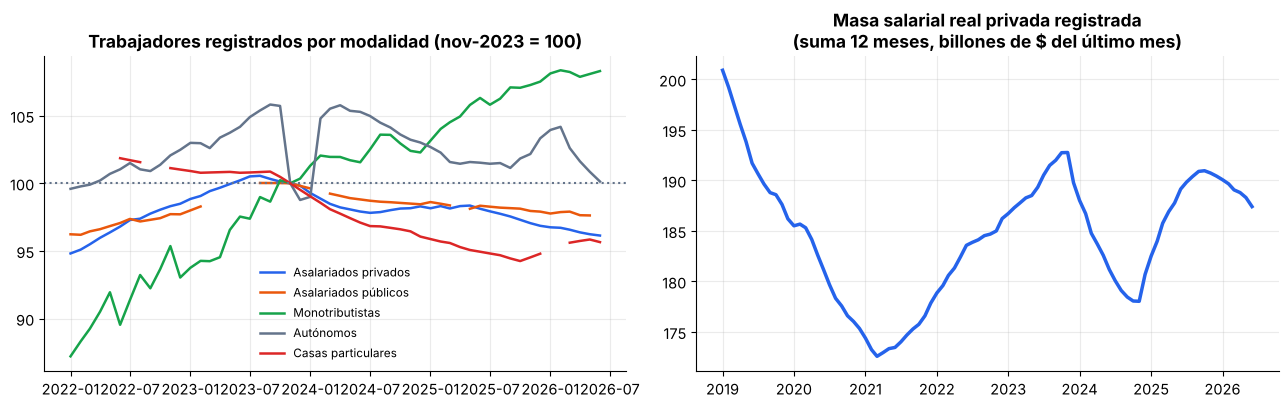

06-2026 contra el mismo mes de 2025: masa salarial real -4.3% (empleo -2.0% y remuneración real -2.3%). Suma de 12 meses: -0.9% interanual.


In [13]:
er = D.empleo_registrado(datos)
ms = D.masa_salarial(datos)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
e2 = er[er.index >= "2022-01-01"]
for k, col in zip(["sipa_asal_priv", "sipa_asal_pub", "sipa_monotributo", "sipa_autonomos", "sipa_casas"],
                  [AZUL, NARANJA, VERDE, GRIS, ROJO]):
    s_ = e2[k] / D._valor_cercano(e2[k], "2023-11-01", 1) * 100
    ax[0].plot(s_.index, s_, color=col, lw=1.8, label=D.MODALIDADES_SIPA[k])
ax[0].axhline(100, color=GRIS, ls=":"); ax[0].set_title("Trabajadores registrados por modalidad (nov-2023 = 100)")
ax[0].legend(frameon=False, fontsize=8.5)
m2 = ms[ms.index >= "2019-01-01"]
ax[1].plot(m2.index, m2["masa_real_12m_bill"], color=AZUL, lw=2.5)
ax[1].set_title("Masa salarial real privada registrada\n(suma 12 meses, billones de $ del último mes)")
plt.tight_layout(); plt.show()
ult = ms.dropna(subset=["masa_real_12m_ia"]).iloc[-1]
f_ = ms["masa_real_12m_ia"].dropna().index[-1]
print(f"{f_:%m-%Y} contra el mismo mes de 2025: masa salarial real {ult.masa_real_ia:.1f}% "
      f"(empleo {ult.empleo_ia:.1f}% y remuneración real {ult.rem_real_ia:.1f}%). "
      f"Suma de 12 meses: {ult.masa_real_12m_ia:.1f}% interanual.")

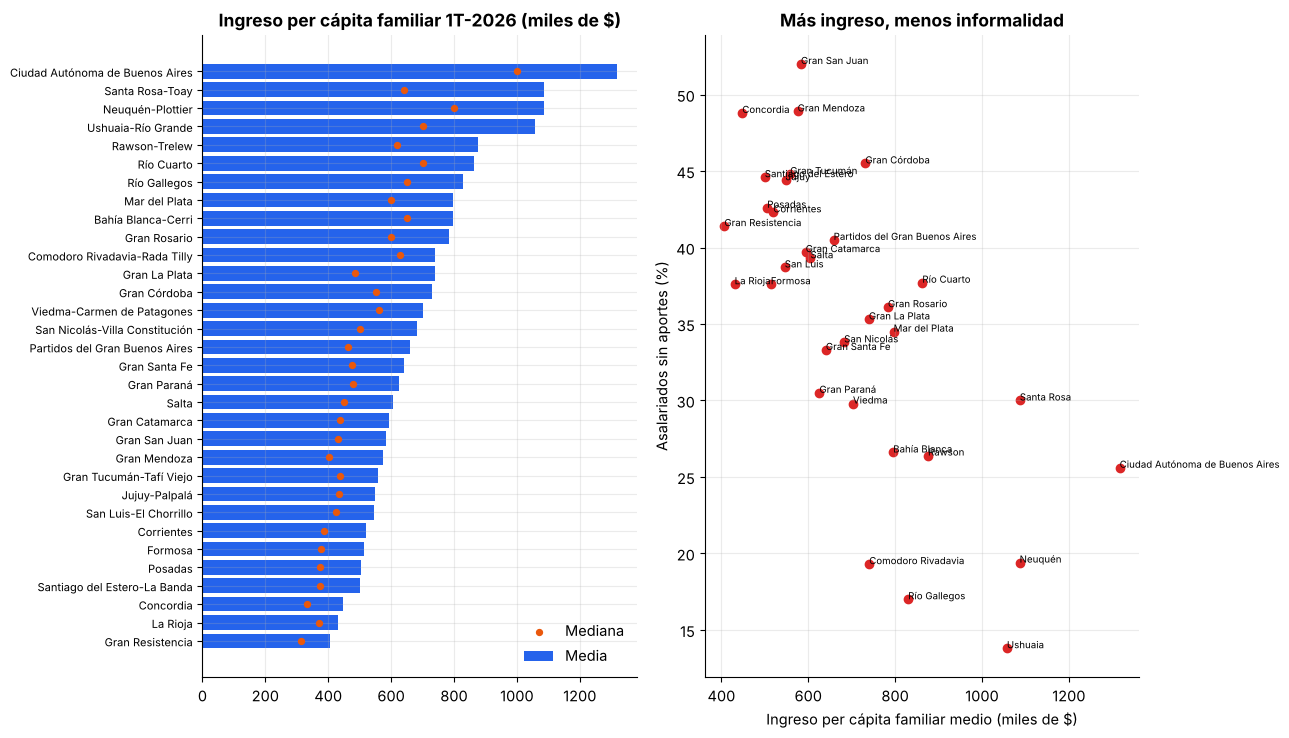

Correlación ingreso–informalidad: -0.7


In [14]:
a = ingresos[ingresos.tipo == "aglomerado"].sort_values("ipcf_medio")
fig, ax = plt.subplots(1, 2, figsize=(13, 7.5))
ax[0].barh(a["nombre"], a["ipcf_medio"] / 1000, color=AZUL, label="Media")
ax[0].scatter(a["ipcf_mediana"] / 1000, a["nombre"], color=NARANJA, zorder=3, s=18, label="Mediana")
ax[0].set_title("Ingreso per cápita familiar 1T-2026 (miles de $)"); ax[0].legend(frameon=False); ax[0].tick_params(axis="y", labelsize=8)
ax[1].scatter(a["ipcf_medio"] / 1000, a["informalidad_asal"], color=ROJO)
for _, r in a.iterrows(): ax[1].annotate(r.nombre.split("-")[0], (r.ipcf_medio / 1000, r.informalidad_asal), fontsize=7)
ax[1].set_xlabel("Ingreso per cápita familiar medio (miles de $)"); ax[1].set_ylabel("Asalariados sin aportes (%)")
ax[1].set_title("Más ingreso, menos informalidad")
plt.tight_layout(); plt.show()
print("Correlación ingreso–informalidad:", round(a[["ipcf_medio", "informalidad_asal"]].corr().iloc[0, 1], 2))

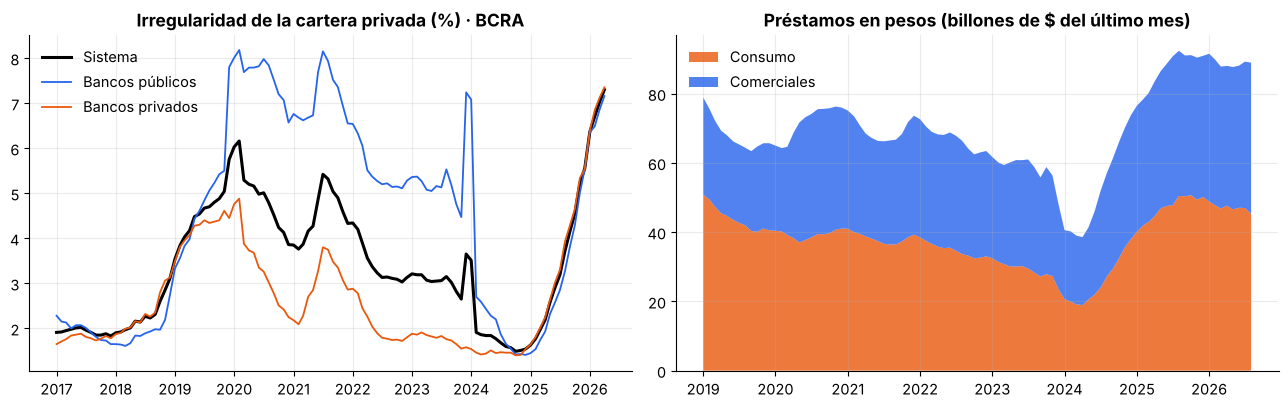

Mora 04-2026: 7.30% (hace un año 2.19%) · crédito real -1.4% i.a. · crédito/PIB 10.5%


,indicador,valor,periodo,fuente
0,Familias (préstamos en situación irregular),12.80,jun-2026,CEPA con datos del BCRA
1,Empresas,3.50,jun-2026,CEPA con datos del BCRA
2,Sistema total (sector privado),7.60,jun-2026,CEPA con datos del BCRA
3,Préstamos personales,15.90,may-2026,CEPA con datos del BCRA
4,Tarjetas de crédito,13.10,may-2026,CEPA con datos del BCRA
5,Billeteras virtuales y proveedores no bancarios,30.10,may-2026,CEPA con datos del BCRA
6,Personas humanas con deuda en mora (más de 90 ...,17.40,jun-2026,Centro de Economía y Comunicación (Mapa de la ...
7,Monto de deuda de personas en mora,19.50,ago-2026,Centro de Economía y Comunicación


In [15]:
cr = D.credito_real(datos); mo = D.mora_nacional(datos)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(mo.index, mo["irreg_total"], color="k", lw=2.2, label="Sistema")
ax[0].plot(mo.index, mo["irreg_publicos"], color=AZUL, lw=1.3, label="Bancos públicos")
ax[0].plot(mo.index, mo["irreg_privados"], color=NARANJA, lw=1.3, label="Bancos privados")
ax[0].set_title("Irregularidad de la cartera privada (%) · BCRA"); ax[0].legend(frameon=False)
c2 = cr[cr.index >= "2019-01-01"]
ax[1].stackplot(c2.index, c2["prest_consumo_real_bill"], c2["prest_comerciales_real_bill"],
                colors=[NARANJA, AZUL], alpha=.8, labels=["Consumo", "Comerciales"])
ax[1].set_title("Préstamos en pesos (billones de $ del último mes)"); ax[1].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
print(f"Mora {mo['irreg_total'].index[-1]:%m-%Y}: {mo['irreg_total'].iloc[-1]:.2f}% (hace un año {mo['irreg_total'].iloc[-13]:.2f}%) · "
      f"crédito real {cr['prest_pesos_real_ia'].dropna().iloc[-1]:.1f}% i.a. · crédito/PIB {cr['credito_pct_pib'].dropna().iloc[-1]:.1f}%")
display(datos.mora_tipos)

### Provincias: PBG, finanzas públicas, salarios y mora

* **PBG (CEPAL):** VAB a precios de 2004 por provincia, 2004-2023. Se calculan participación, PBG por habitante (país = 100) con el Censo 2022 y crecimiento real. No hay una serie oficial homogénea más reciente: el PBG 2025 en pesos es una estimación (participación 2023 × PIB nominal 2025).
* **Finanzas provinciales 2025 (DNAP):** resultado primario y financiero sobre ingresos, **autonomía fiscal** (tributos propios / ingresos), **dependencia de Nación** (coparticipación y transferencias / ingresos), peso de la masa salarial pública, regalías e intereses.
* **Masa salarial privada provincial:** asalariados registrados (SIPA) × salario promedio (OEDE), marzo 2026.

In [16]:
pb = D.resumen_pbg(datos)
fp = D.fiscal_provincial(datos)
cols = ["provincia", "pbg_participacion", "pbg_pc_indice", "pbg_pc_usd", "pbg_crec_anual_2004"]
display(pb[cols].sort_values("pbg_participacion", ascending=False).round(1).head(8))
cols_f = ["provincia", "resultado_primario_pct_ing", "resultado_financiero_pct_ing", "autonomia_fiscal",
          "dependencia_nacional", "personal_pct_gasto", "gasto_pct_pbg"]
fp[cols_f].sort_values("resultado_financiero_pct_ing").round(1)

,provincia,pbg_participacion,pbg_pc_indice,pbg_pc_usd,pbg_crec_anual_2004
0,Buenos Aires,32.40,84.90,"12,635.30",2.00
1,CABA,20.10,294.90,"43,901.30",1.80
6,Córdoba,8.00,96.10,"14,300.80",2.10
20,Santa Fe,7.80,101.00,"15,032.40",1.50
14,Neuquén,3.90,249.90,"37,195.80",2.90
12,Mendoza,3.30,73.90,"10,999.00",1.00
7,Entre Ríos,2.70,87.20,"12,987.20",2.30
16,Salta,2.00,62.10,"9,242.80",2.50


,provincia,resultado_primario_pct_ing,resultado_financiero_pct_ing,autonomia_fiscal,dependencia_nacional,personal_pct_gasto,gasto_pct_pbg
23,Tierra del Fuego,-15.40,-16.30,21.60,50.80,52.80,20.60
6,Chubut,-4.70,-8.20,21.60,35.00,53.70,18.40
19,Santa Cruz,-6.30,-6.30,16.10,39.70,49.80,20.70
1,Buenos Aires,-2.50,-5.90,40.70,42.10,40.20,13.30
5,Chaco,-1.30,-5.80,10.20,72.80,47.10,32.30
12,Mendoza,-2.90,-5.70,30.80,53.90,41.80,17.00
4,Corrientes,-5.00,-5.20,12.20,71.20,45.40,29.00
15,Río Negro,-3.00,-4.50,28.50,59.30,64.00,21.00
11,La Rioja,-2.20,-2.80,11.30,85.80,50.30,28.50
7,Entre Ríos,0.00,-2.80,20.30,59.50,44.90,21.60


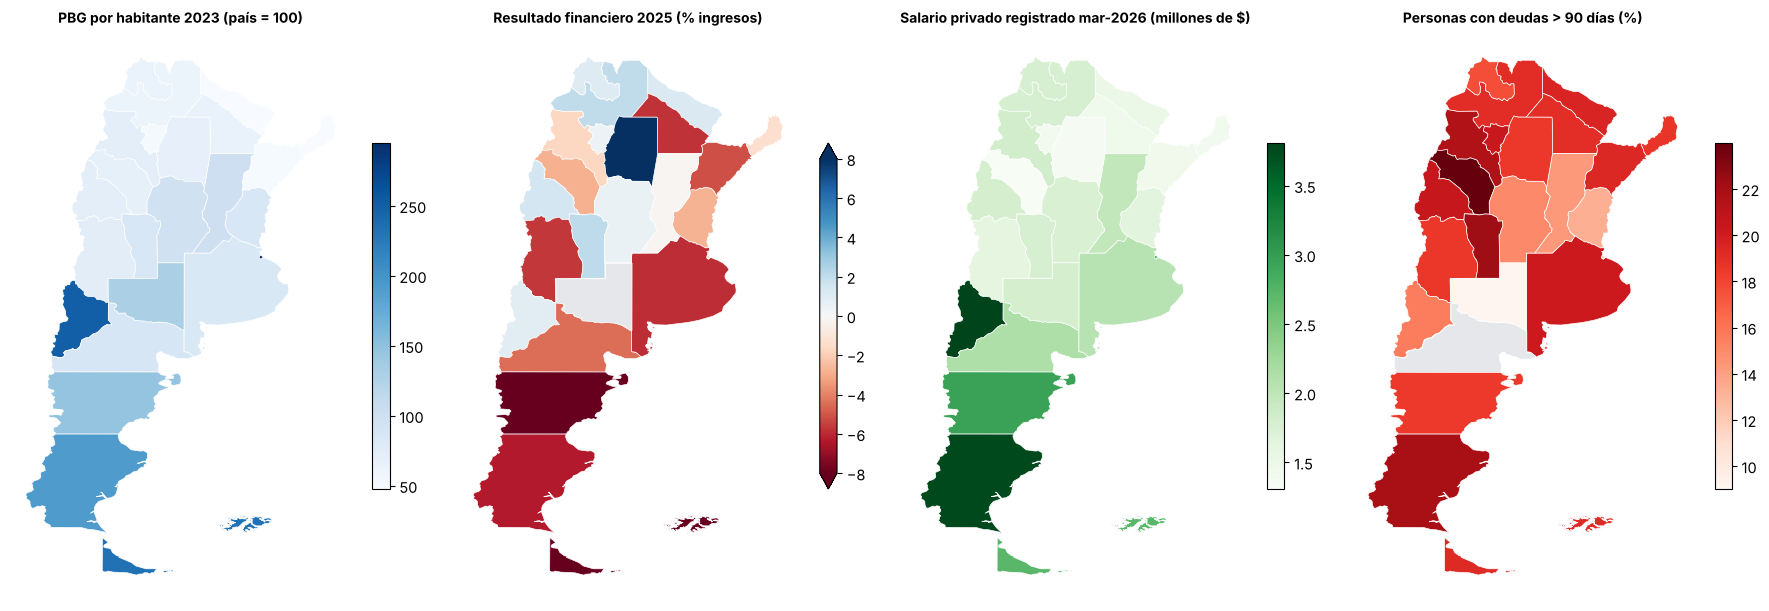

In [17]:
gdf = gpd.GeoDataFrame.from_features(datos.geojson["features"]).merge(datos.provincias, on="provincia")
gdf["salario_millones"] = gdf["salario_privado_mar2026"] / 1e6
fig, ax = plt.subplots(1, 4, figsize=(18, 8))
for eje, col, cmap, tit, kw in [
        (ax[0], "pbg_pc_indice", "Blues", "PBG por habitante 2023 (país = 100)", {}),
        (ax[1], "resultado_financiero_pct_ing", "RdBu", "Resultado financiero 2025 (% ingresos)", dict(vmin=-8, vmax=8)),
        (ax[2], "salario_millones", "Greens", "Salario privado registrado mar-2026 (millones de $)", {}),
        (ax[3], "mora_personas_jun2026", "Reds", "Personas con deudas > 90 días (%)", {})]:
    gdf.plot(column=col, cmap=cmap, legend=True, ax=eje, edgecolor="white", linewidth=.5,
             legend_kwds={"shrink": .45}, missing_kwds={"color": "#e5e7eb"}, **kw)
    eje.set_title(tit, fontsize=10); eje.set_axis_off()
plt.tight_layout(); plt.show()

## 4. Modelos

### 4.1 Pronóstico de inflación (series de tiempo + machine learning)
Se comparan cuatro modelos con **validación *rolling origin*** (los últimos 12 meses, pronóstico a un paso): ingenuo, media móvil de 3 meses, **ARIMA(p,0,q)** con orden elegido por AIC y una **regresión Ridge** con rezagos de inflación general, núcleo, regulados, tipo de cambio y dummies de mes (entrenada desde 2017). La estimación se limita al régimen posterior a la desinflación (desde jun-2024).

In [18]:
pron = M.pronosticar_inflacion(datos.mensual, horizonte=6)
display(pron.ranking.round(3))
print("Modelo elegido:", pron.modelo_elegido, "| orden ARIMA:", pron.orden_arima)
display(pron.pronostico.round(2))
print(f"Inflación acumulada proyectada (6 meses): {M.inflacion_acumulada(pron.pronostico['media']):.1f}%")

,MAE (p.p.),RMSE (p.p.)
Ingenuo (último dato),0.31,0.38
ARIMA,0.36,0.49
Media móvil 3m,0.41,0.47
Ridge con rezagos (ML),0.56,0.70


Modelo elegido: Ingenuo (último dato) | orden ARIMA: (1, 0, 0)


,media,inf_80,sup_80,inf_95,sup_95,media_arima
2026-10-01,1.94,1.46,2.42,1.20,2.68,2.10
2026-11-01,1.94,1.26,2.62,0.90,2.98,2.22
2026-12-01,1.94,1.10,2.77,0.66,3.22,2.33
2027-01-01,1.94,0.98,2.90,0.47,3.41,2.41
2027-02-01,1.94,0.86,3.02,0.29,3.59,2.48
2027-03-01,1.94,0.76,3.12,0.13,3.75,2.53


Inflación acumulada proyectada (6 meses): 12.2%


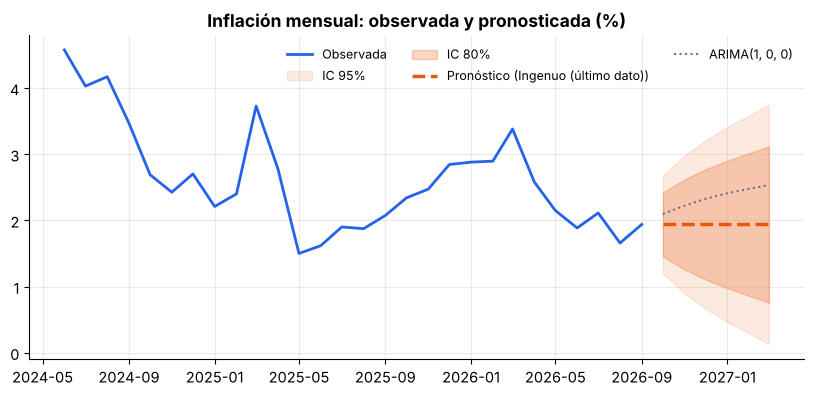

In [19]:
h = pron.historia[pron.historia.index >= "2024-06-01"]; fc = pron.pronostico
fig, ax = plt.subplots()
ax.plot(h.index, h, color=AZUL, lw=2, label="Observada")
ax.fill_between(fc.index, fc.inf_95, fc.sup_95, color=NARANJA, alpha=.12, label="IC 95%")
ax.fill_between(fc.index, fc.inf_80, fc.sup_80, color=NARANJA, alpha=.25, label="IC 80%")
ax.plot(fc.index, fc.media, color=NARANJA, lw=2.5, ls="--", label=f"Pronóstico ({pron.modelo_elegido})")
ax.plot(fc.index, fc.media_arima, color=GRIS, lw=1.5, ls=":", label=f"ARIMA{pron.orden_arima}")
ax.set_title("Inflación mensual: observada y pronosticada (%)"); ax.legend(frameon=False, ncol=3, fontsize=9); plt.show()

**Lectura:** en un régimen corto y relativamente estable, el pronóstico **ingenuo** le gana a ARIMA y al modelo de ML. Es un resultado habitual en la literatura de pronóstico de inflación (Atkeson-Ohanian, 2001): los modelos más complejos solo agregan valor cuando hay suficiente historia homogénea. El ARIMA aporta las bandas de incertidumbre y una trayectoria que revierte a la media del período.

### 4.2 Ley de Okun (MCO con errores HAC)
$\Delta u_t = \alpha + \beta\, g_t + \varepsilon_t$, con $\Delta u$ = variación interanual de la desocupación (p.p.) y $g$ = crecimiento interanual del PIB (%). Se excluye la pandemia (2020 y 1S-2021).

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0751      0.261      0.288      0.773      -0.436       0.586
crec_pib      -0.2199      0.066     -3.333      0.001      -0.349      -0.091

β = -0.220: +1 p.p. de crecimiento ⇒ 0.22 p.p. menos de desocupación. R² = 0.50
Crecimiento que deja estable el desempleo: 0.3%


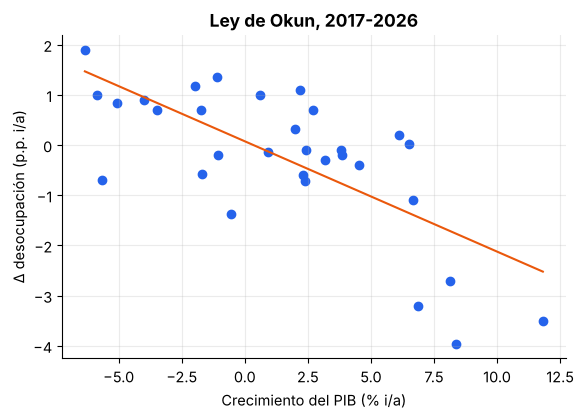

In [20]:
okun, od = M.ley_de_okun(datos.trimestral)
print(okun.summary().tables[1])
b = okun.params
print(f"\nβ = {b['crec_pib']:.3f}: +1 p.p. de crecimiento ⇒ {-b['crec_pib']:.2f} p.p. menos de desocupación. R² = {okun.rsquared:.2f}")
print(f"Crecimiento que deja estable el desempleo: {-b['const']/b['crec_pib']:.1f}%")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(od.crec_pib, od.delta_u, color=AZUL)
xx = np.linspace(od.crec_pib.min(), od.crec_pib.max(), 50); ax.plot(xx, b["const"] + b["crec_pib"] * xx, color=NARANJA)
ax.set_xlabel("Crecimiento del PIB (% i/a)"); ax.set_ylabel("Δ desocupación (p.p. i/a)"); ax.set_title("Ley de Okun, 2017-2026"); plt.show()

### 4.3 ¿Qué explica las diferencias de pobreza entre aglomerados?
Corte transversal de los 31 aglomerados (pobreza 1S-2026 contra tasas laborales 2T-2026), MCO con errores robustos HC1.

In [21]:
rp, rd = M.regresion_pobreza(datos.aglomerados)
print(rp.summary().tables[1]); print(f"R² = {rp.rsquared:.2f}, n = {int(rp.nobs)}")

                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           107.5747     17.831      6.033      0.000      72.626     142.523
tasa_desocupacion    -0.2790      0.386     -0.723      0.470      -1.035       0.477
tasa_empleo          -1.7269      0.400     -4.313      0.000      -2.512      -0.942
tasa_subocupacion     0.2716      0.306      0.887      0.375      -0.328       0.871
R² = 0.43, n = 32


### 4.4 Tipología de aglomerados (aprendizaje no supervisado)
K-means sobre seis variables estandarizadas (actividad, empleo, desocupación, subocupación, pobreza, indigencia). Se reporta el coeficiente de silueta para distintos *k* y se proyecta en dos componentes principales.

Silueta por k: {2: 0.26, 3: 0.264, 4: 0.264, 5: 0.261, 6: 0.285}


,tasa_actividad,tasa_empleo,tasa_desocupacion,tasa_subocupacion,personas_pobreza,personas_indigencia
cluster,,,,,,
Alta pobreza,44.60,41.10,7.60,10.50,41.30,10.60
Mercado laboral dinámico,53.40,51.00,4.40,7.40,15.40,2.20
Baja participación laboral,45.10,43.10,4.40,7.00,32.40,3.70
Alto desempleo y subocupación,50.20,45.90,8.60,14.60,28.90,5.90


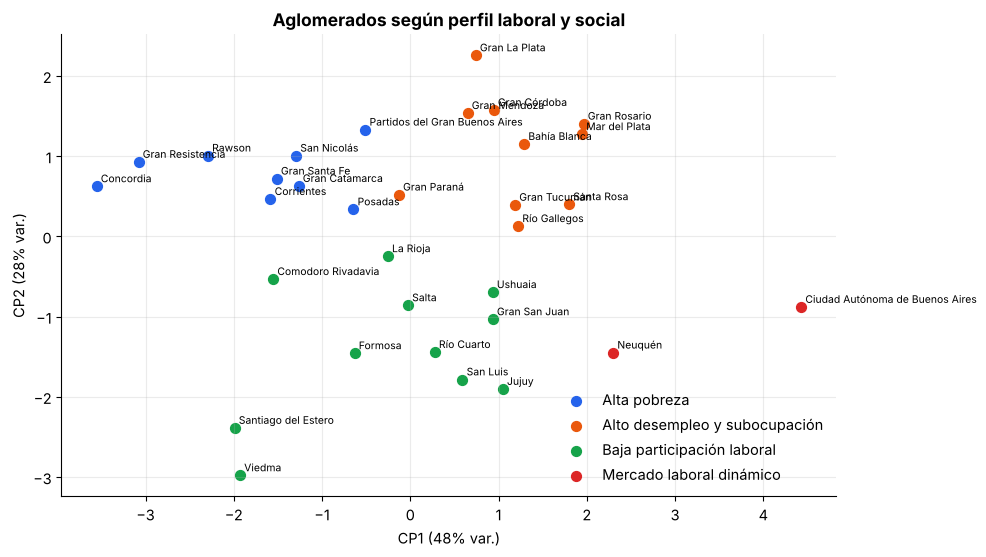

In [22]:
cl, perf, sil, ev = M.clusters_aglomerados(datos.aglomerados, k=4)
print("Silueta por k:", sil.round(3).to_dict())
display(perf)
fig, ax = plt.subplots(figsize=(10, 6))
for (perfil, g), col in zip(cl.groupby("perfil"), [AZUL, NARANJA, VERDE, ROJO, GRIS]):
    ax.scatter(g.pc1, g.pc2, color=col, label=perfil, s=50)
    for _, r in g.iterrows(): ax.annotate(r.nombre.split("-")[0], (r.pc1, r.pc2), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"CP1 ({ev[0]*100:.0f}% var.)"); ax.set_ylabel(f"CP2 ({ev[1]*100:.0f}% var.)")
ax.set_title("Aglomerados según perfil laboral y social"); ax.legend(frameon=False); plt.show()

### 4.5 ¿Por qué la mora difiere entre provincias?
Corte transversal de 23 provincias: % de personas con deudas de más de 90 días (jun-2026) contra el logaritmo del ingreso per cápita familiar (EPH 1T-2026); en (2) se controla por desocupación e informalidad. MCO con errores HC1.

In [23]:
mora_s, mora_c, mora_d = M.regresion_mora(datos.provincias)
print(mora_s.summary().tables[1]); print(f"R² = {mora_s.rsquared:.2f}, n = {int(mora_s.nobs)}")
print(mora_c.summary().tables[1]); print(f"R² = {mora_c.rsquared:.2f}")
b = mora_s.params["log_ipcf"]
print(f"\n+10% de ingreso per cápita familiar ⇒ {-b*np.log(1.1):.2f} p.p. menos de personas en mora")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    113.4250     28.838      3.933      0.000      56.904     169.946
log_ipcf      -7.1138      2.172     -3.275      0.001     -11.372      -2.856
R² = 0.39, n = 23
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           163.2646     39.332      4.151      0.000      86.175     240.354
log_ipcf            -10.3943      2.789     -3.727      0.000     -15.861      -4.928
tasa_desocupacion    -0.1014      0.148     -0.685      0.494      -0.392       0.189
informalidad_asal    -0.1458      0.081     -1.804      0.071      -0.304       0.013
R² = 0.49

+10% de ingreso per cápita familiar ⇒ 0.68 p.p. menos de personas en mora


### 4.6 Convergencia regional (β y σ)
$g_i = a + b\,\ln y_{i,2010} + \varepsilon_i$, con $g$ = crecimiento anual del PBG per cápita 2010-2022 (años censales, así la población es observada y no proyectada). $b<0$ indica convergencia β; la velocidad implícita es $\lambda = -\ln(1 + bT/100)/T$ y la vida media $\ln 2/\lambda$.

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          5.8909      2.901      2.031      0.042       0.205      11.576
log_pbg_pc_ini    -0.6696      0.313     -2.136      0.033      -1.284      -0.055
β = -0.670 (p = 0.033) · λ = 0.70% anual · vida media ≈ 99 años
σ (desvío del log PBG per cápita): 0.545 en 2010 → 0.511 en 2022


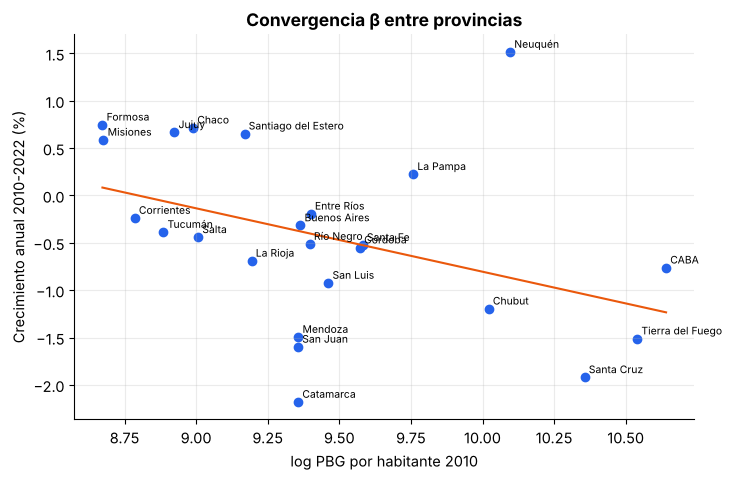

In [24]:
conv = M.convergencia_pbg(D.pbg_largo(datos), pd.read_csv(D.DATA_DIR / "provincias_base.csv"))
print(conv.modelo.summary().tables[1])
print(f"β = {conv.beta:.3f} (p = {conv.p_valor:.3f}) · λ = {conv.velocidad*100:.2f}% anual · vida media ≈ {conv.vida_media:.0f} años")
print(f"σ (desvío del log PBG per cápita): {conv.sigma_inicial:.3f} en 2010 → {conv.sigma_final:.3f} en 2022")
fig, ax = plt.subplots(figsize=(8, 5))
cd = conv.datos
ax.scatter(cd.log_pbg_pc_ini, cd.crec_anual, color=AZUL)
xx = np.linspace(cd.log_pbg_pc_ini.min(), cd.log_pbg_pc_ini.max(), 50)
ax.plot(xx, conv.modelo.params["Intercept"] + conv.beta * xx, color=NARANJA)
for _, r in cd.iterrows(): ax.annotate(r.provincia, (r.log_pbg_pc_ini, r.crec_anual), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("log PBG por habitante 2010"); ax.set_ylabel("Crecimiento anual 2010-2022 (%)"); ax.set_title("Convergencia β entre provincias"); plt.show()

## 5. Componente de IA generativa

`econoar.ia` arma una lista de **hechos verificados** (dato + período + fuente) y se la pasa a Claude como único contexto, con la instrucción de no inventar cifras. Sin clave de API (`ANTHROPIC_API_KEY`), el asistente usa un motor local de reglas, así el prototipo funciona igual.

In [25]:
hechos = ia.hechos_clave(datos, pron)
texto, motor = ia.generar_informe(hechos)
print(f"[motor: {motor}]\n"); print(texto)

[motor: plantilla]

**Precios y salarios.** Inflación (IPC INDEC) de septiembre 2026: 1,9% mensual, 33,4% interanual, 23,6% acumulada en el año. Núcleo: 1,7% mensual. Inflación interanual por región: GBA 33,5%, Pampeana 33,1%, Noreste 36,9%, Noroeste 33,6%, Cuyo 33,0%, Patagonia 30,3%. Pronóstico econoAR (Ingenuo (último dato)): 1,9% para octubre 2026 (IC 80%: 1,5–2,4%). Salario real registrado privado (julio 2026): índice 96,6 (nov-2023 = 100). Masa salarial real del empleo privado registrado (SIPA, 12 meses a junio 2026): -0,9% interanual; remuneración bruta promedio real -2,3% i.a. y empleo asalariado privado -2,0% i.a.

**Actividad, empleo y pobreza.** PIB 2T-2026: 2,0% interanual (precios constantes). PIB 2025: 4,5%. EMAE julio 2026: -1,4% interanual (serie original). Industria (IPI, agosto 2026): -3,2% i.a.; construcción (ISAC, agosto 2026): -4,4% i.a. Producto Bruto Geográfico (CEPAL, 2023): las cinco mayores participaciones en el VAB son Buenos Aires 32,4%, CABA 20,1%, Córdoba 

In [26]:
for q in ["¿Cuánto fue la inflación del último mes?", "¿Cómo está el empleo en Neuquén y en Tierra del Fuego?",
          "¿Hay superávit fiscal?", "¿Cómo viene la mora?"]:
    r, motor = ia.responder(q, hechos)
    print(f"P: {q}\nR ({motor}):\n{r}\n" + "-" * 80)

P: ¿Cuánto fue la inflación del último mes?
R (local):
• Inflación (IPC INDEC) de septiembre 2026: 1,9% mensual, 33,4% interanual, 23,6% acumulada en el año. Núcleo: 1,7% mensual.
• Inflación interanual por región: GBA 33,5%, Pampeana 33,1%, Noreste 36,9%, Noroeste 33,6%, Cuyo 33,0%, Patagonia 30,3%.
• Pronóstico econoAR (Ingenuo (último dato)): 1,9% para octubre 2026 (IC 80%: 1,5–2,4%).
--------------------------------------------------------------------------------
P: ¿Cómo está el empleo en Neuquén y en Tierra del Fuego?
R (local):
• Neuquén: desocupación 3,2% y pobreza 19,6% (aglomerado Neuquén-Plottier); empleo privado registrado 154,7 mil (5,2% i.a.); exportaciones 1S-2026 USD 4.304 M (42,5%); población 710.814. PBG 2023 3,9% del país, por habitante 250 (país = 100). Salario privado mar-2026 $3.808.627; ingreso per cápita familiar medio 1T-2026 $1.086.593; informalidad asalariada 19,4%. Mora de personas jun-2026 15,6%. Finanzas 2025: resultado financiero 0,9% de los ingresos, aut

## 6. Resultados principales

1. **Precios:** la inflación mensual se estabilizó en torno a 1,5–2% desde mediados de 2024 (septiembre 2026: 1,9% m/m; 33,4% i/a; 23,6% acumulada en el año). Regulados (43,3% i/a) siguen por encima de la núcleo (31,6%); el Noreste es la región con más inflación interanual (36,9%).
2. **Actividad y trabajo:** el PIB creció 2,0% i/a en el 2T-2026, pero la desocupación subió a 7,9% (igual al 1T-2025 y el nivel más alto desde 2021) con más informalidad laboral (45,0%). La Ley de Okun estimada (β ≈ −0,22) indica que hace falta crecer más de lo observado para bajar el desempleo.
3. **Territorio:** la heterogeneidad es enorme: desocupación de 0,7% (Viedma) a 11,5% (Gran Rosario); pobreza de 11,1% (CABA) a 56,2% (Concordia). En empleo formal, solo Neuquén, Río Negro, San Juan, La Rioja y Tucumán crecen interanualmente, mientras Tierra del Fuego cae 13%.
4. **Pobreza:** en el corte transversal, la **tasa de empleo** es la variable que más explica la pobreza de un aglomerado (cada punto adicional de empleo ≈ −1,7 p.p. de pobreza), más que la desocupación.
5. **Fiscal:** superávit primario de 1,8% del PIB en 2024 y 1,4% en 2025, con superávit financiero acotado (0,3% y 0,2%) por el peso de los intereses.
6. **Pronóstico:** con datos hasta agosto, el modelo proyectaba 1,7% para septiembre (IC 80%: 1,2–2,1%); el INDEC publicó 1,9%, dentro de la banda. Con el dato nuevo, el modelo ganador (ingenuo) proyecta 1,9% mensual desde octubre (IC 80% de octubre: 1,5–2,4%) y 12,2% acumulado a marzo 2027.
7. **Empleo formal e ingresos:** desde nov-2023 hay 246 mil asalariados privados registrados menos (−3,9%) y 169 mil monotributistas más (+8,3%): el empleo formal se recompone hacia el cuentapropismo. La masa salarial real privada de 12 meses cae 0,9% interanual a junio 2026 (empleo −2,0% y remuneración real −2,3%). El ingreso per cápita familiar medio del 1T-2026 va de $406.752 (Gran Resistencia) a $1.316.909 (CABA), y los aglomerados con más ingreso tienen menos informalidad.
8. **Crédito y mora:** la irregularidad de la cartera privada pasó de 2,2% a 7,3% en un año (abril 2026); en las familias llega a 12,8% y en las billeteras virtuales a 30%. El crédito real ya cae interanualmente. Entre provincias, la mora de las personas va de 9,0% (La Pampa) a 24,0% (La Rioja) y se explica en buena medida por el ingreso: +10% de ingreso per cápita ≈ −0,7 p.p. de mora (R² 0,39).
9. **PBG y finanzas provinciales:** Buenos Aires, CABA y Córdoba concentran el 60,5% del producto; el PBG por habitante de CABA es 6,2 veces el de Misiones. Hay convergencia β débil (β = −0,67, p = 0,03) con una vida media de ~99 años. En 2025 las provincias cerraron con déficit financiero consolidado de 2,1% de los ingresos; solo 9 de 23 tuvieron superávit, y en promedio el 58% de sus recursos viene de Nación (autonomía fiscal mediana: 21,6%).